# Online Retail II: Business Analysis
**Goal:** Answer key business questions about revenue, products, countries, and customers.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Load the clean files we saved in the cleaning notebook
df = pd.read_csv("../data/processed/clean_data.csv", parse_dates=["InvoiceDate"])
df_customers = pd.read_csv("../data/processed/clean_customers.csv", parse_dates=["InvoiceDate"])
cancellations = pd.read_csv("../data/processed/cancellations.csv")

print("Rows loaded:", len(df))

Rows loaded: 1003214


Question 1: What are our headline numbers?

In [2]:
total_revenue = df["Revenue"].sum()
total_orders = df["Invoice"].nunique()      # nunique = number of unique values
total_customers = df_customers["Customer ID"].nunique()
avg_order_value = total_revenue / total_orders

print("Total revenue:", round(total_revenue, 2))
print("Total orders:", total_orders)
print("Total customers:", total_customers)
print("Average order value:", round(avg_order_value, 2))

Total revenue: 19642692.15
Total orders: 39516
Total customers: 5852
Average order value: 497.08


In [3]:
cancelled_orders = cancellations["Invoice"].nunique()
cancel_rate = cancelled_orders / (total_orders + cancelled_orders) * 100

print("Cancelled orders:", cancelled_orders)
print("Cancellation rate:", round(cancel_rate, 2), "%")

Cancelled orders: 8292
Cancellation rate: 17.34 %


In [4]:
# Count how many different orders each customer made
orders_per_customer = df_customers.groupby("Customer ID")["Invoice"].nunique()

# A repeat customer has more than 1 order
repeat_rate = (orders_per_customer > 1).mean() * 100

print("Repeat purchase rate:", round(repeat_rate, 2), "%")

Repeat purchase rate: 72.35 %


Question 2: How does revenue change over time?

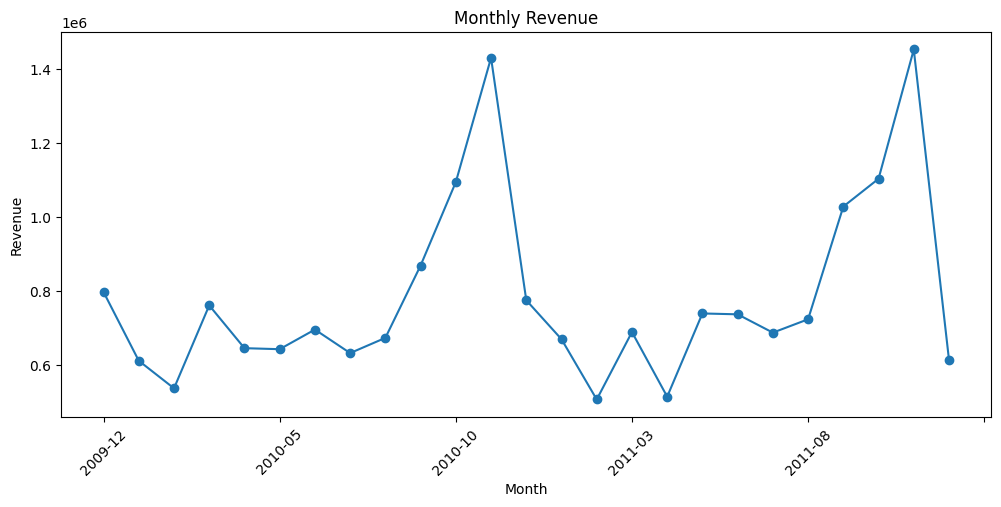

In [5]:
# Group by month and add up the revenue
monthly_revenue = df.groupby("YearMonth")["Revenue"].sum()

monthly_revenue.plot(kind="line", marker="o", figsize=(12, 5))
plt.title("Monthly Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.show()

Question 3: Which products and countries earn the most?

In [6]:
top_products = df.groupby("Description")["Revenue"].sum().sort_values(ascending=False).head(10)
top_products

Description
REGENCY CAKESTAND 3 TIER               330590.32
WHITE HANGING HEART T-LIGHT HOLDER     260990.22
PAPER CRAFT , LITTLE BIRDIE            168469.60
PARTY BUNTING                          148318.28
JUMBO BAG RED RETROSPOT                148073.47
ASSORTED COLOUR BIRD ORNAMENT          129324.49
PAPER CHAIN KIT 50'S CHRISTMAS         117760.29
MEDIUM CERAMIC TOP STORAGE JAR          81700.92
CHILLI LIGHTS                           80540.88
ROTATING SILVER ANGELS T-LIGHT HLDR     71300.40
Name: Revenue, dtype: float64

In [7]:
top_countries = df.groupby("Country")["Revenue"].sum().sort_values(ascending=False).head(10)
top_countries

Country
United Kingdom    16799849.90
EIRE                623414.16
Netherlands         549773.41
Germany             383289.00
France              311090.29
Australia           167800.01
Spain                97766.75
Switzerland          94024.59
Sweden               86319.14
Denmark              67422.69
Name: Revenue, dtype: float64

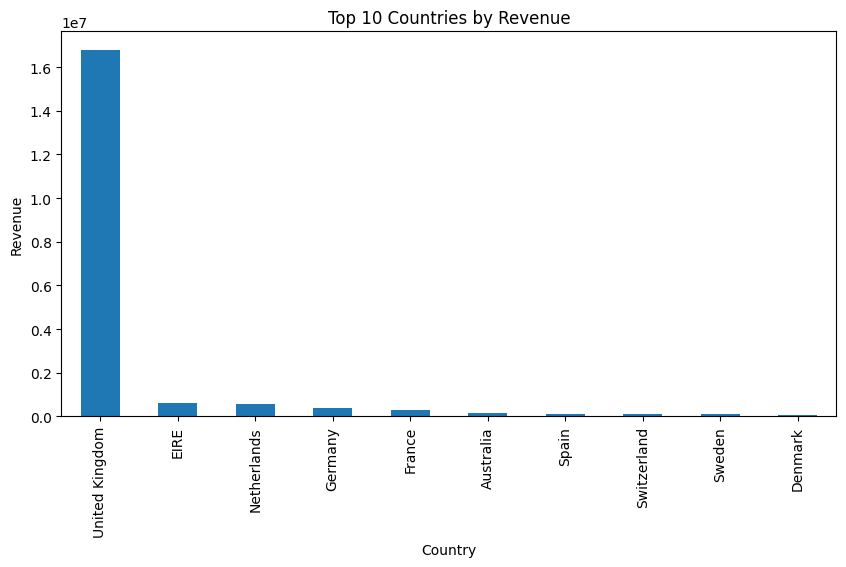

In [8]:
top_countries.plot(kind="bar", figsize=(10, 5))
plt.title("Top 10 Countries by Revenue")
plt.ylabel("Revenue")
plt.show()

In [9]:
   df[df["Description"] == "PAPER CRAFT , LITTLE BIRDIE"][["Invoice", "Quantity", "Price", "InvoiceDate"]]

,Invoice,Quantity,Price,InvoiceDate
1001747,581483,80995,2.08,2011-12-09 09:15:00


## Customer Segmentation: RFM Analysis

In [12]:
# We need a "today" date to measure recency from.
# Use the day after the last order in the data.
snapshot_date = df_customers["InvoiceDate"].max() + pd.Timedelta(days=1)
print("Snapshot date:", snapshot_date)

# One row per customer with their last purchase date, number of orders, and total spend
rfm = df_customers.groupby("Customer ID").agg(
    LastPurchase=("InvoiceDate", "max"),
    Frequency=("Invoice", "nunique"),
    Monetary=("Revenue", "sum"),
).reset_index()

# Recency = days between their last purchase and the snapshot date
rfm["Recency"] = (snapshot_date - rfm["LastPurchase"]).dt.days

rfm.head()

Snapshot date: 2011-12-10 12:50:00


,Customer ID,LastPurchase,Frequency,Monetary,Recency
0,12346,2011-01-18 10:01:00,3,77352.96,326
1,12347,2011-12-07 15:52:00,8,4921.53,2
2,12348,2011-09-25 13:13:00,5,1658.40,75
3,12349,2011-11-21 09:51:00,3,3678.69,19
4,12350,2011-02-02 16:01:00,1,294.40,310


In [13]:
# qcut splits customers into 5 equal-sized groups.
# For Recency, FEWER days is better, so the labels run 5 down to 1.
rfm["R"] = pd.qcut(rfm["Recency"], 5, labels=[5, 4, 3, 2, 1]).astype(int)

# For Frequency and Monetary, MORE is better.
# We rank first because many customers have exactly 1 order, and qcut can't split identical values.
rfm["F"] = pd.qcut(rfm["Frequency"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm["M"] = pd.qcut(rfm["Monetary"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)

rfm.head()

,Customer ID,LastPurchase,Frequency,Monetary,Recency,R,F,M
0,12346,2011-01-18 10:01:00,3,77352.96,326,2,3,5
1,12347,2011-12-07 15:52:00,8,4921.53,2,5,4,5
2,12348,2011-09-25 13:13:00,5,1658.40,75,3,4,4
3,12349,2011-11-21 09:51:00,3,3678.69,19,5,3,5
4,12350,2011-02-02 16:01:00,1,294.40,310,2,1,2


In [14]:
def assign_segment(row):
    if row["R"] >= 4 and row["F"] >= 4:
        return "Champions"          # bought recently, buy often
    elif row["R"] >= 3 and row["F"] >= 3:
        return "Loyal Customers"    # fairly recent, fairly frequent
    elif row["R"] >= 3:
        return "New / Promising"    # bought recently, but not often yet
    elif row["F"] >= 3:
        return "At Risk"            # used to buy often, haven't been back
    else:
        return "Lost"               # haven't bought in a long time, and rarely did

# Apply the function to every row (axis=1 means "row by row")
rfm["Segment"] = rfm.apply(assign_segment, axis=1)

rfm["Segment"].value_counts()

Segment
Lost               1508
Champions          1476
Loyal Customers    1207
New / Promising     833
At Risk             828
Name: count, dtype: int64

In [15]:
segment_summary = rfm.groupby("Segment").agg(
    Customers=("Customer ID", "count"),
    TotalRevenue=("Monetary", "sum"),
    AvgRecency=("Recency", "mean"),
    AvgFrequency=("Frequency", "mean"),
    AvgSpend=("Monetary", "mean"),
).round(1)

# What share of customers and revenue does each segment hold?
segment_summary["PctCustomers"] = (segment_summary["Customers"] / segment_summary["Customers"].sum() * 100).round(1)
segment_summary["PctRevenue"] = (segment_summary["TotalRevenue"] / segment_summary["TotalRevenue"].sum() * 100).round(1)

segment_summary.sort_values("TotalRevenue", ascending=False)

,Customers,TotalRevenue,AvgRecency,AvgFrequency,AvgSpend,PctCustomers,PctRevenue
Segment,,,,,,,
Champions,1476,11816435.5,20.4,15.6,8005.7,25.2,69.2
Loyal Customers,1207,2421467.1,78.2,5.4,2006.2,20.6,14.2
At Risk,828,1592996.0,368.0,5.0,1923.9,14.1,9.3
Lost,1508,620259.0,456.9,1.2,411.3,25.8,3.6
New / Promising,833,617410.3,64.1,1.4,741.2,14.2,3.6


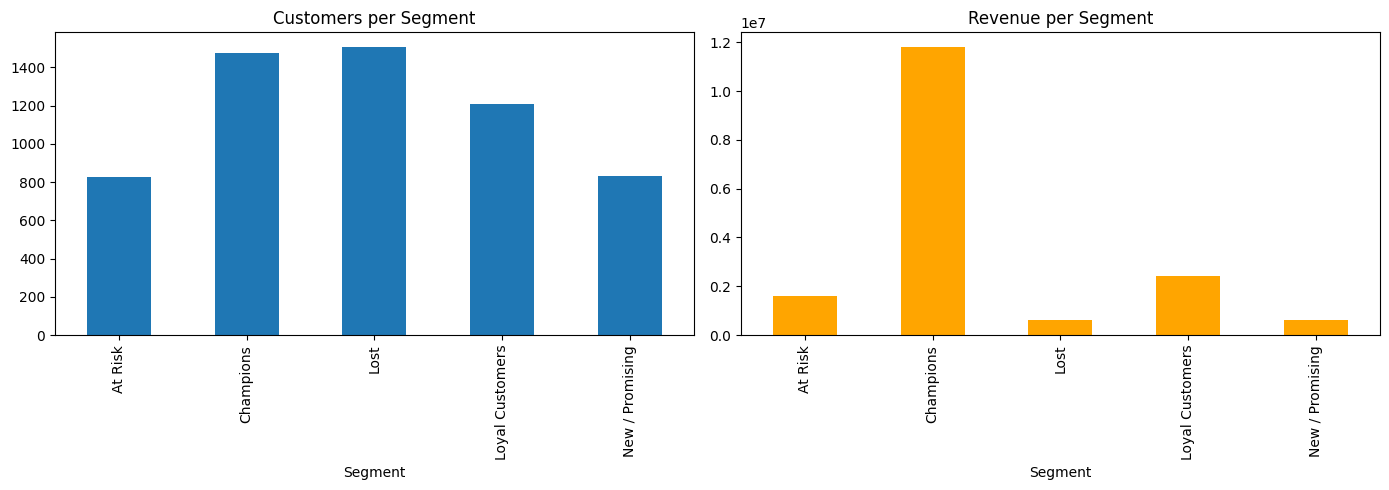

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

segment_summary["Customers"].plot(kind="bar", ax=axes[0])
axes[0].set_title("Customers per Segment")

segment_summary["TotalRevenue"].plot(kind="bar", ax=axes[1], color="orange")
axes[1].set_title("Revenue per Segment")

plt.tight_layout()
plt.show()

In [17]:
rfm.to_csv("../data/processed/rfm_customers.csv", index=False)
segment_summary.to_csv("../data/processed/rfm_segment_summary.csv")
print("Saved!")

Saved!
